# Milestone M2 — Audit Data, EDA, Uji Kebocoran & Model Baseline (Topik T3-A)
**Kelompok 6 — Deep Learning A (Sistem Informasi, UTM)**  
*Anggota:* Attala Alif Ramadhani Tri Hida (`230441100144`), Nafaul Hernanda Romadlona (`240441100125`), M. Rafly Kurniawan (`240441100086`), Naufal Husain (`240441100038`)


In [1]:
# Clone repositori di Google Colab & pasang dependensi
import os, sys, subprocess

REPO_URL = "https://github.com/attaramadhani/UAS-DL-Kelompok6-T3A-WBC-DomainShift.git"
REPO_NAME = "UAS-DL-Kelompok6-T3A-WBC-DomainShift"

if "google.colab" in sys.modules and not os.path.exists(REPO_NAME):
    subprocess.run(["git", "clone", REPO_URL], check=True)
if os.path.exists(REPO_NAME):
    os.chdir(REPO_NAME)
sys.path.insert(0, os.getcwd())

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
import torch
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


PyTorch: 2.14.1+cu130 | CUDA: True Tesla T4


## 1. Unduh Dataset Resmi (Mendeley) & Jalankan Audit Data + Split Tetap (`seed=42`)


In [2]:
from src.audit_eda import main as run_audit
run_audit()


Audit selesai! Laporan tersimpan di: /content/UAS-DL-Kelompok6-T3A-WBC-DomainShift/logs/data_audit_report.json
{
  "dataset": "Zheng et al. (2018) WBC Segmentation (DOI: 10.17632/w7cvnmn4c5.1)",
  "split_seed": 42,
  "split_files": {
    "D1": "splits/zheng_d1_split.csv",
    "D2": "splits/zheng_d2_split.csv"
  },
  "leakage_check": {
    "total_images": 400,
    "split_counts": {
      "D1": {
        "train": 210,
        "val": 45,
        "test": 45
      },
      "D2": {
        "train": 70,
        "val": 15,
        "test": 15
      }
    },
    "cross_split_leakage_exact": 0,
    "cross_split_leakage_dhash_le_4bits": 0,
    "cross_domain_near_duplicates_le_4bits": 0,
    "within_train_exact_duplicates_grouped": [
      [
        "D1/112(train)",
        "D1/139(train)"
      ]
    ]
  },
  "domain_1_eda": {
    "domain": "D1",
    "count": 300,
    "unique_dimensions_count": 30,
    "dimensions_summary": {
      "120x120": 224,
      "112x116": 12,
      "116x120": 10,
      "1

## 2. Tampilkan Grafik EDA & Preview Macenko / Reinhard Stain Normalization


=== fig1_sample_overlay_d1_d2.png ===


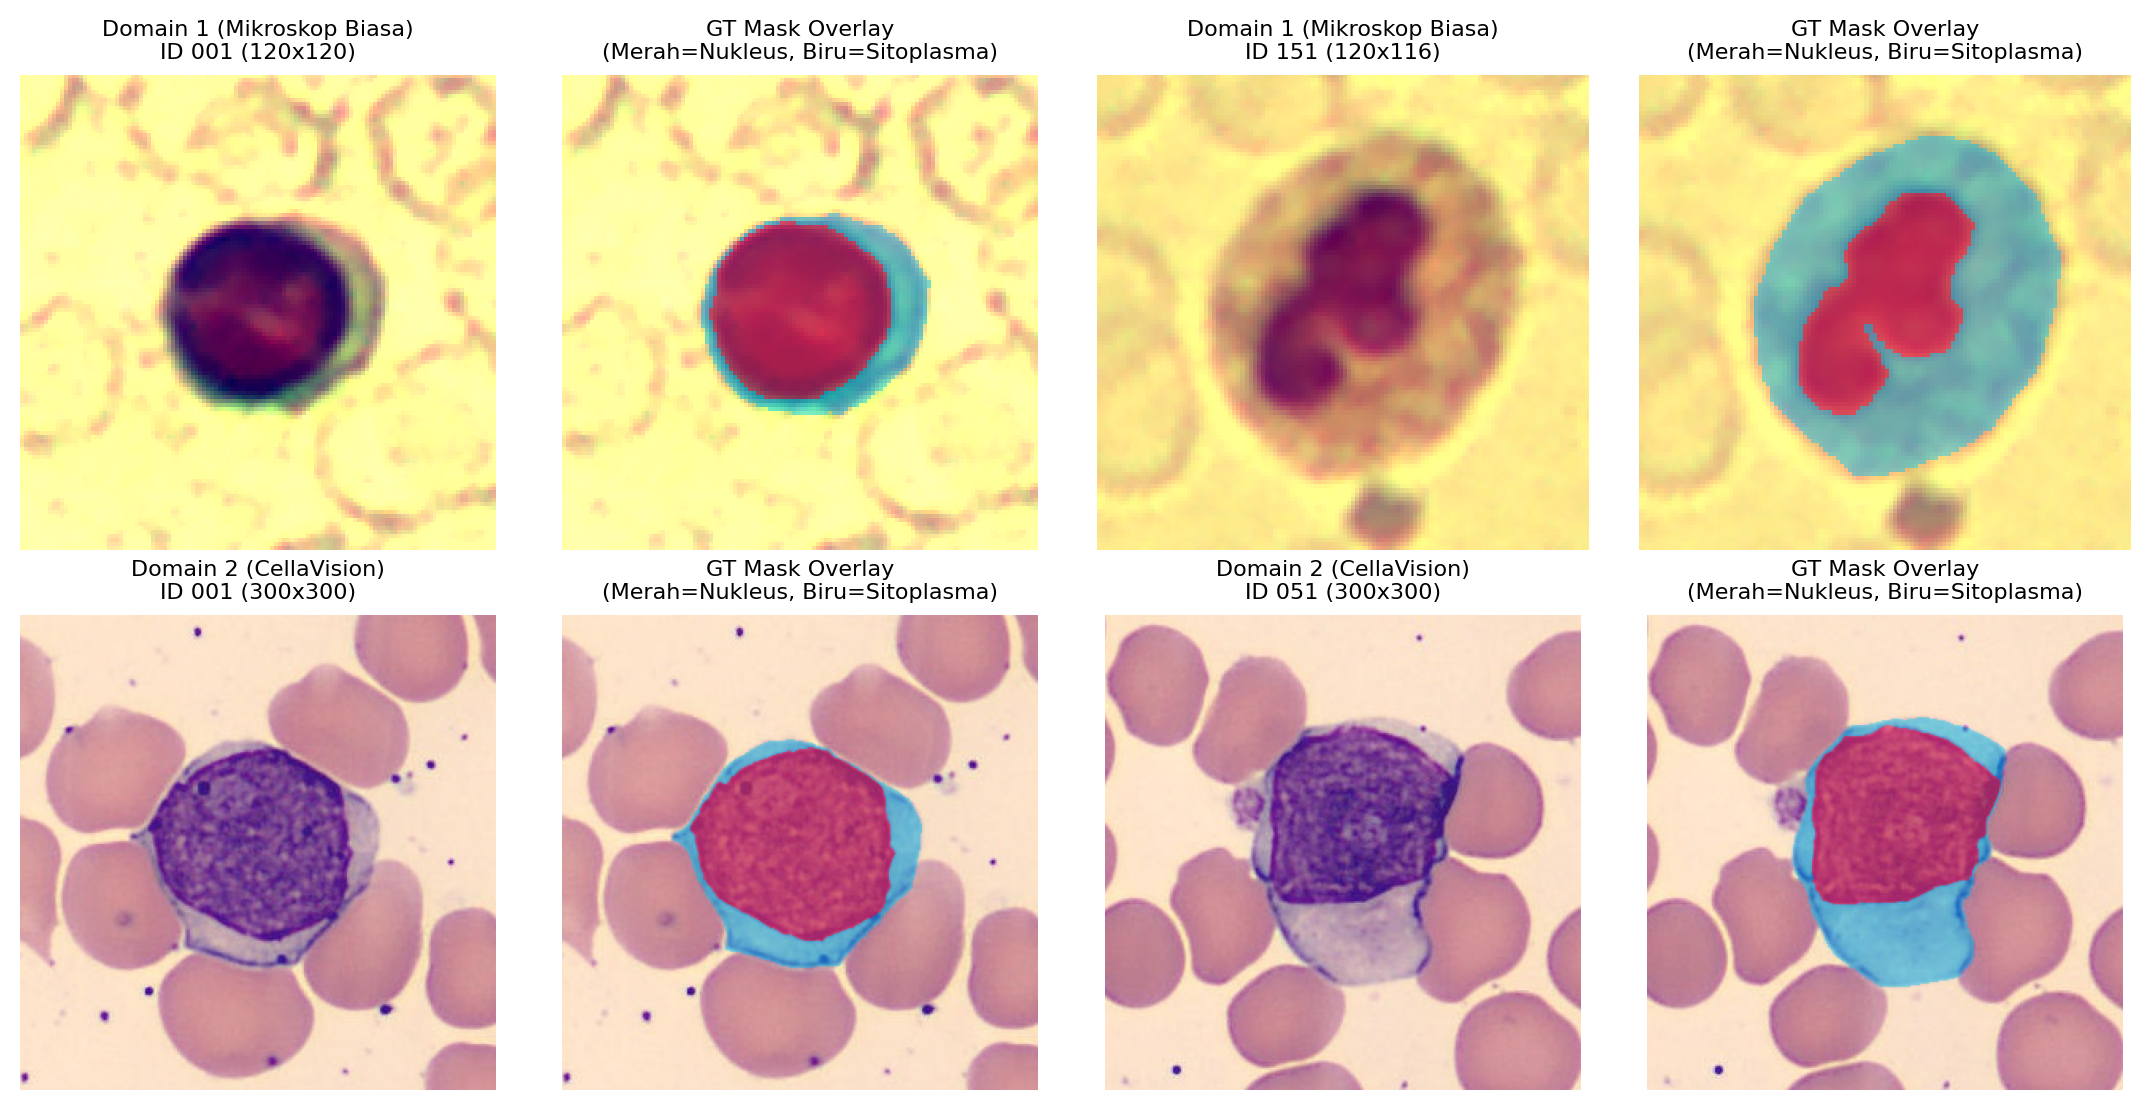

=== fig2_eda_distributions.png ===


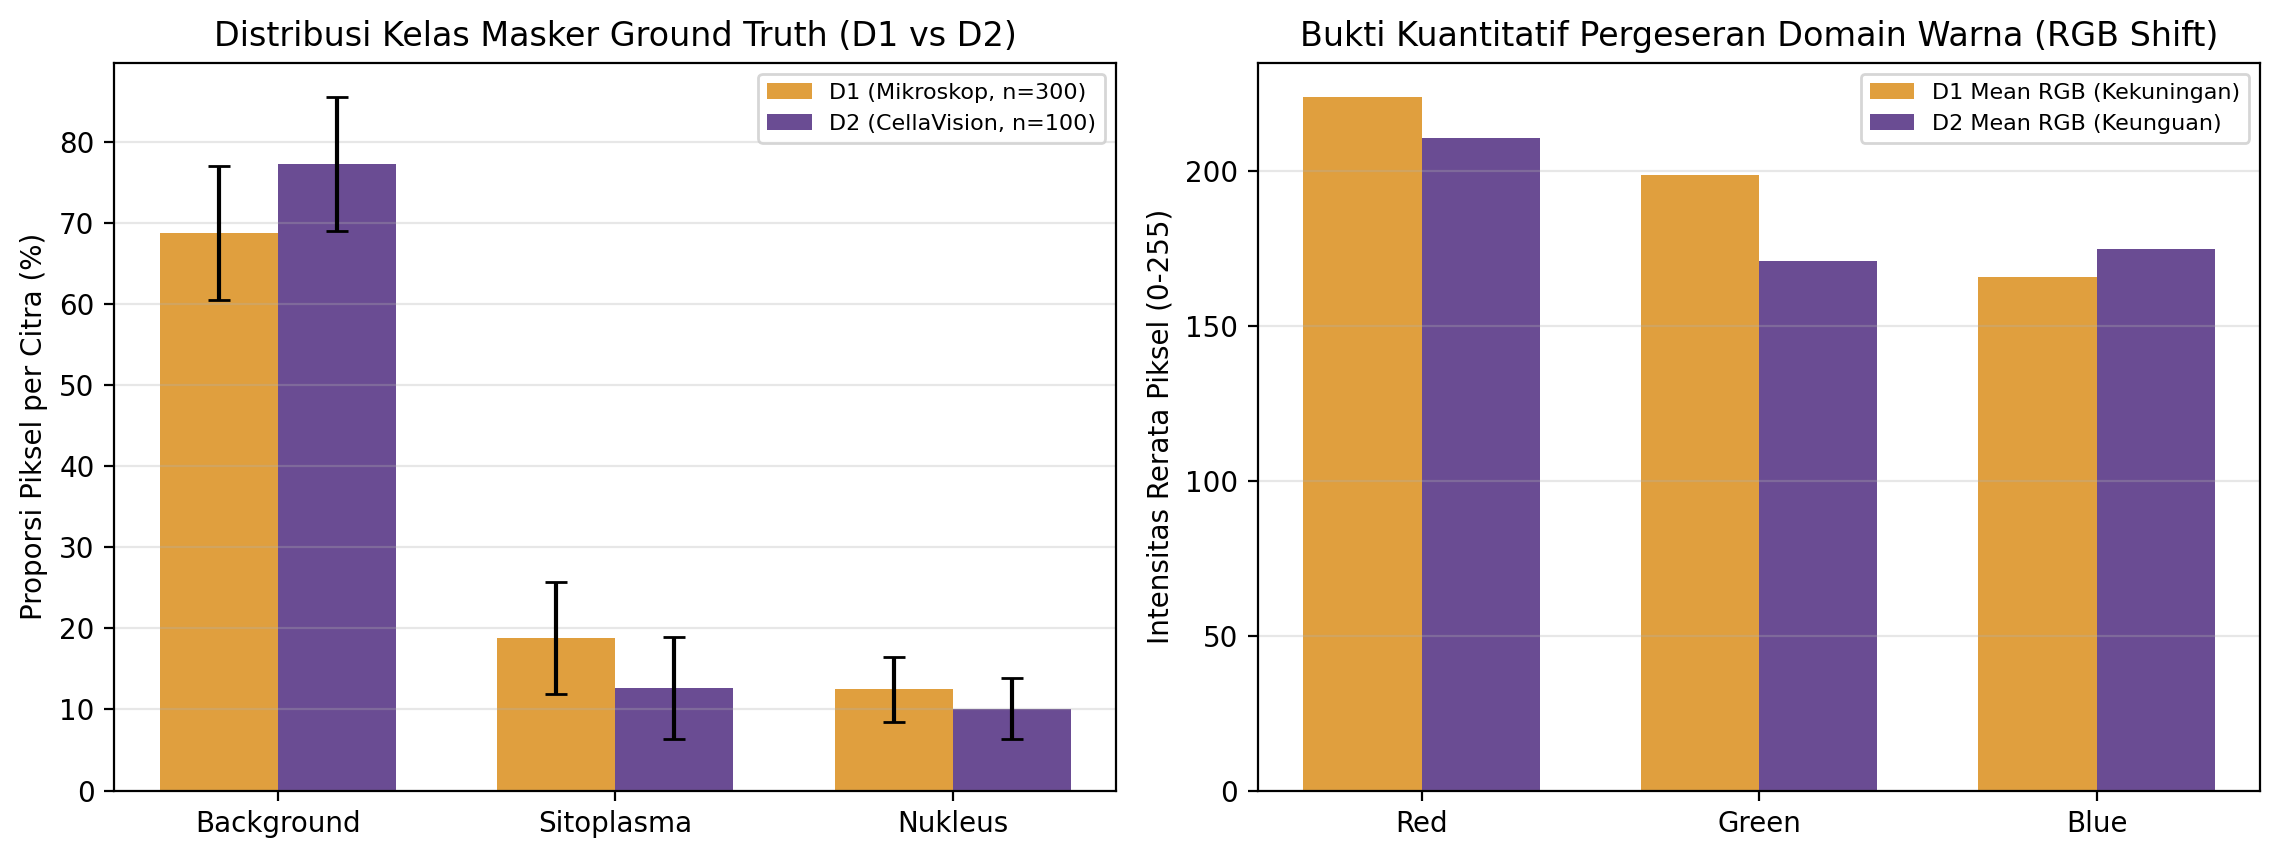

=== fig3_stain_norm_preview.png ===


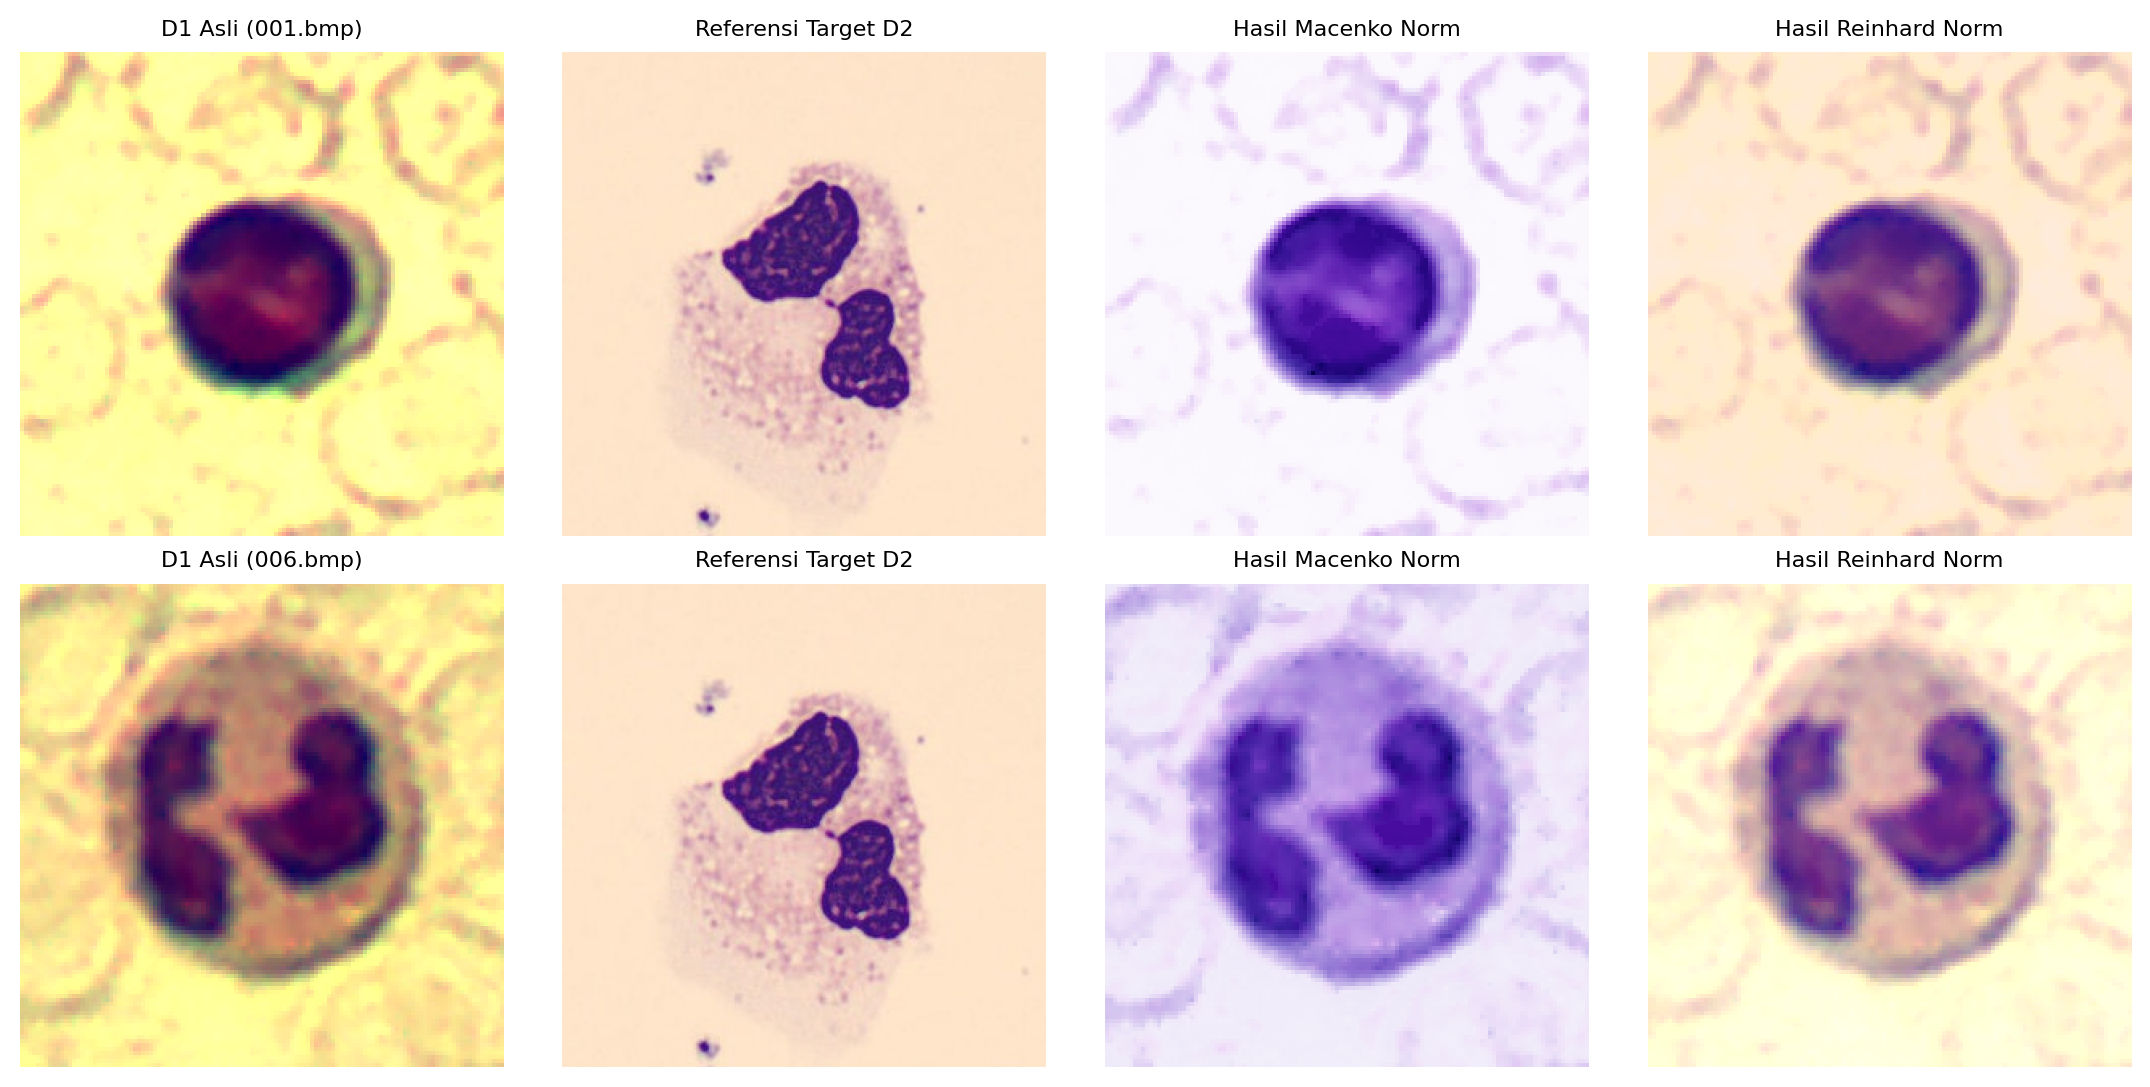

In [3]:
from IPython.display import Image, display
for fig_name in ["fig1_sample_overlay_d1_d2.png", "fig2_eda_distributions.png", "fig3_stain_norm_preview.png"]:
    print("===", fig_name, "===")
    display(Image(filename=f"docs/figures/{fig_name}"))


## 3. Latih & Evaluasi 1 Model Baseline (U-Net ResNet-34: Train D1 -> Uji In-Domain D1 & Cross-Domain D2)


In [4]:
from src.dataset import download_and_extract_zheng
from src.trainer import run_experiment

domain_dirs = download_and_extract_zheng("data")
split_csvs = {"D1": "splits/zheng_d1_split.csv", "D2": "splits/zheng_d2_split.csv"}

baseline_res = run_experiment(
    run_name="M2_Baseline_UNet_D1_to_D2",
    owner="Kelompok 6 (Baseline M2)",
    domain_dirs=domain_dirs,
    split_csvs=split_csvs,
    train_domain="D1",
    target_domain="D2",
    arch="unet",
    encoder_name="resnet34",
    loss_name="ce_dice",
    aug_mode="geom",
    seed=42,
    epochs=30,
    log_csv_path="logs/m2_baseline_runs.csv",
)
print("Ringkasan Baseline M2:", baseline_res["row"])


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Ringkasan Baseline M2: {'run_name': 'M2_Baseline_UNet_D1_to_D2', 'owner': 'Kelompok 6 (Baseline M2)', 'train_domain': 'D1', 'target_domain': 'D2', 'arch': 'unet', 'encoder': 'resnet34', 'freeze_encoder': False, 'loss': 'ce_dice', 'aug_mode': 'geom', 'input_size': 256, 'seed': 42, 'status': 'success', 'val_dice_fg': 0.9581, 'in_dice_nuc': 0.9703, 'in_dice_cyto': 0.9435, 'in_miou_fg': 0.9185, 'cross_dice_nuc': 0.6726, 'cross_dice_cyto': 0.3482, 'cross_miou_fg': 0.4281, 'cross_hd95_nuc': 20.66, 'cross_hd95_cyto': 81.1, 'params_m': 24.437, 'latency_ms': 7.831, 'gpu': 'Tesla T4', 'duration_sec': 160.03}
